In [1]:
import os
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

import torch
import torch.nn as nn
import torch.optim as optim

from tqdm import tqdm

In [2]:
PARQUET_PATH = "D:\\Projects\\Wonder fund\\wnn_connectome_starterpack\\wnn_connectome_starterpack\\datasets\\train.parquet"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# Baseline settings
HIDDEN_SIZE = 128
NUM_LAYERS = 1

CHUNK_SIZE = 1024

LEARNING_RATE = 1e-3

EPOCHS = 5

N_TRAIN_SEQS = 100
N_VAL_SEQS = 500

Device: cuda


In [3]:
i0_p = [f"i0_p{i}" for i in range(22)]
i0_v = [f"i0_v{i}" for i in range(22)]
i0_dp = [f"i0_dp{i}" for i in range(4)]
i0_dv = [f"i0_dv{i}" for i in range(4)]

i1_p = [f"i1_p{i}" for i in range(22)]
i1_v = [f"i1_v{i}" for i in range(22)]
i1_dp = [f"i1_dp{i}" for i in range(4)]
i1_dv = [f"i1_dv{i}" for i in range(4)]

additional = [f"a{i}" for i in range(8)]

INPUT_COLS = (
    i0_p +
    i0_v +
    i0_dp +
    i0_dv +
    i1_p +
    i1_v +
    i1_dp +
    i1_dv +
    additional
)

TARGET_COLS = ["t0", "t1"]

print("Number of input features:", len(INPUT_COLS))
print("Targets:", TARGET_COLS)

Number of input features: 112
Targets: ['t0', 't1']


In [4]:
pf = pq.ParquetFile(PARQUET_PATH)

print("Number of sequences:", pf.num_row_groups)
print("Rows:", pf.metadata.num_rows)

Number of sequences: 10607
Rows: 212140000


In [5]:
def load_sequence(pf, row_group_idx):
    
    table = pf.read_row_group(
        row_group_idx,
        columns=INPUT_COLS + TARGET_COLS
    )
    
    df = table.to_pandas()
    
    X = df[INPUT_COLS].to_numpy(
        dtype=np.float32,
        copy=True
    )
    
    y = df[TARGET_COLS].to_numpy(
        dtype=np.float32,
        copy=True
    )
    
    del table
    del df
    
    return X, y

In [6]:
X, y = load_sequence(pf, 0)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X dtype:", X.dtype)
print("y dtype:", y.dtype)

X shape: (20000, 112)
y shape: (20000, 2)
X dtype: float32
y dtype: float32


In [7]:
class BaselineGRU(nn.Module):

    def __init__(
        self,
        input_size=112,
        hidden_size=128,
        num_layers=1
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.head = nn.Linear(
            hidden_size,
            2
        )

    def forward(self, x, hidden=None):

        out, hidden = self.gru(
            x,
            hidden
        )

        pred = self.head(out)

        return pred, hidden

In [8]:
model = BaselineGRU(
    input_size=112,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS
).to(DEVICE)

print(model)

BaselineGRU(
  (gru): GRU(112, 128, batch_first=True)
  (head): Linear(in_features=128, out_features=2, bias=True)
)


In [9]:
criterion = nn.MSELoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

In [10]:
def train_one_sequence(model, X, y):

    model.train()

    # numpy → torch
    X = torch.from_numpy(X).unsqueeze(0).to(DEVICE)
    y = torch.from_numpy(y).unsqueeze(0).to(DEVICE)

    hidden = None

    total_loss = 0.0
    n_chunks = 0

    # WARMUP: steps 0 → 98
    with torch.no_grad():

        _, hidden = model(
            X[:, :99, :],
            hidden
        )

    # PREDICTION REGION: 99 → 19999

    start = 99

    while start < X.shape[1]:

        end = min(
            start + CHUNK_SIZE,
            X.shape[1]
        )

        x_chunk = X[:, start:end, :]
        y_chunk = y[:, start:end, :]

        # Forward
        pred, hidden = model(
            x_chunk,
            hidden
        )

        # Loss
        loss = criterion(
            pred,
            y_chunk
        )

        # Backprop
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        # Detach hidden state
        hidden = hidden.detach()

        total_loss += loss.item()
        n_chunks += 1

        start = end

    return total_loss / n_chunks

In [11]:
history =  []

for epoch in range(EPOCHS):

    epoch_loss = 0.0

    for seq_idx in tqdm(
        range(N_TRAIN_SEQS),
        desc=f"Epoch {epoch+1}"
    ):

        X, y = load_sequence(
            pf,
            seq_idx
        );

        loss = train_one_sequence(
            model,
            X,
            y
        )

        epoch_loss += loss

        del X
        del y

    epoch_loss /= N_TRAIN_SEQS
    history.append(epoch_loss)
    print(
        f"Epoch {epoch+1} "
        f"Average Loss: {epoch_loss:.6f}"
    )

Epoch 1: 100%|██████████| 100/100 [00:17<00:00,  5.64it/s]


Epoch 1 Average Loss: 0.924138


Epoch 2: 100%|██████████| 100/100 [00:10<00:00,  9.75it/s]


Epoch 2 Average Loss: 0.892244


Epoch 3: 100%|██████████| 100/100 [00:09<00:00, 10.48it/s]


Epoch 3 Average Loss: 0.875859


Epoch 4: 100%|██████████| 100/100 [00:13<00:00,  7.57it/s]


Epoch 4 Average Loss: 0.863125


Epoch 5: 100%|██████████| 100/100 [00:10<00:00,  9.33it/s]

Epoch 5 Average Loss: 0.852440


trials on it when mera `N_TRAIN_SEQS = 10` tha-->
1. try to increase the no of epoches at 50 epoches we get loss till 0.112840
2. 


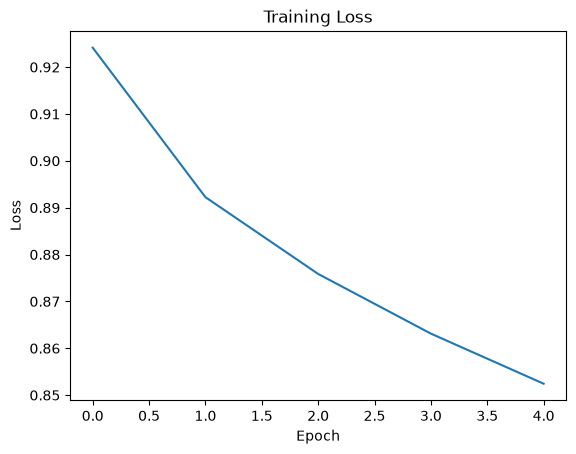

In [12]:
import matplotlib.pyplot as plt

plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()